# 0b — Follow one invented example from spikes to a prediction

**Software teaching example, not neuroscience evidence.** We will carry the same tiny
dataset through counting, source separation, assembly, normalization, a fixed linear
projection and a fixed decoder. All timestamps and parameters are invented. Nothing
is optimized, no PCA basis is fitted, and no historical model or lab file is loaded.

Read this after [the research guide](00_research_guide.ipynb), then use
[Chapter 1](01_pseudopopulation.ipynb) for the real construction contract. The example
has two blocks with one unit each, two 100-ms bins and two endpoint conditions. It
deliberately lacks the production workflow's full condition set and minimum source
support: it is a hand calculation, not a dataset that passed those gates.

The labels `1→2` and `2→1` mean **ordered start/goal conditions**, not observed paths.
We supply them explicitly here. Actual labels require the provisional marker derivation
and predecessor embargo explained in Chapter 1. A source is one recording; a
pseudorow joins different recordings using their known condition.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')

def show_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

# Declare split, condition and block BEFORE making counts or pseudorows.
# These IDs identify invented examples, not lab sessions or people.
sources = [
    ('L_A_t', 'L', 'train', '1->2', [-.01, .02, .10, .16, .20]),
    ('L_B_t', 'L', 'train', '2->1', [.01, .04, .08, .12]),
    ('R_A_t', 'R', 'train', '1->2', [.03, .06, .09, .15]),
    ('R_B_t', 'R', 'train', '2->1', [.02, .11, .14]),
    ('L_A_d1', 'L', 'development', '1->2', [.02]),
    ('L_A_d2', 'L', 'development', '1->2', [.01, .04, .08, .14]),
    ('L_B_d', 'L', 'development', '2->1', [.03, .06, .09, .11, .16]),
    ('R_A_d', 'R', 'development', '1->2', [.01, .03, .08, .12, .15]),
    ('R_B_d', 'R', 'development', '2->1', [.02, .14]),
]
edges = np.array([0., .1, .2])
blocks = ('L', 'R')
by_id = {row[0]: row for row in sources}
show_table(['Source', 'Block/unit', 'Split', 'Known pair', 'Invented timestamps (s)'], sources)
print('Nine source trials; two units; two bins. No model training.')

| Source | Block/unit | Split | Known pair | Invented timestamps (s) |
| --- | --- | --- | --- | --- |
| L_A_t | L | train | 1->2 | [-0.01, 0.02, 0.1, 0.16, 0.2] |
| L_B_t | L | train | 2->1 | [0.01, 0.04, 0.08, 0.12] |
| R_A_t | R | train | 1->2 | [0.03, 0.06, 0.09, 0.15] |
| R_B_t | R | train | 2->1 | [0.02, 0.11, 0.14] |
| L_A_d1 | L | development | 1->2 | [0.02] |
| L_A_d2 | L | development | 1->2 | [0.01, 0.04, 0.08, 0.14] |
| L_B_d | L | development | 2->1 | [0.03, 0.06, 0.09, 0.11, 0.16] |
| R_A_d | R | development | 1->2 | [0.01, 0.03, 0.08, 0.12, 0.15] |
| R_B_d | R | development | 2->1 | [0.02, 0.14] |

Nine source trials; two units; two bins. No model training.


## 1. Count events, keeping zero distinct from unrecorded

Bins are `[0,.1)` and `[.1,.2)` seconds from the invented cue onset. For `L_A_t`,
`.02` enters bin 0; `.10` and `.16` enter bin 1. The exact boundary event `.10` is
counted once. `−.01` and `.20` are outside these bins, so the result is **[1,2]**,
not [1,3]. We preserve those outside events in the original list.
Every invented source is assumed recorded throughout both bins, giving .1 s of
observed exposure per bin; a gap in recording would require a different contract.

The source tensor has shape **9 sources × 2 unit columns × 2 bins**. A left-block
source observed only the left unit. Its right-unit entries are NaN with a false
observation mask; they are not zero spikes. The counts for `L_A_t` therefore appear
as `[[1,2], [NaN,NaN]]`. By contrast, `L_A_d1` yields [1,0]: its second bin was
observed but contained no spike. No cross-session measurement is created at this step.

| Source | Bin 0 count | Bin 1 count |
| --- | --- | --- |
| L_A_t | 1 | 2 |
| L_B_t | 3 | 1 |
| R_A_t | 3 | 1 |
| R_B_t | 1 | 2 |
| L_A_d1 | 1 | 0 |
| L_A_d2 | 3 | 1 |
| L_B_d | 3 | 2 |
| R_A_d | 3 | 2 |
| R_B_d | 1 | 1 |

Source tensor: (9, 2, 2) | observation mask: (9, 2)
First source tensor slice:
[[ 1.  2.]
 [nan nan]]


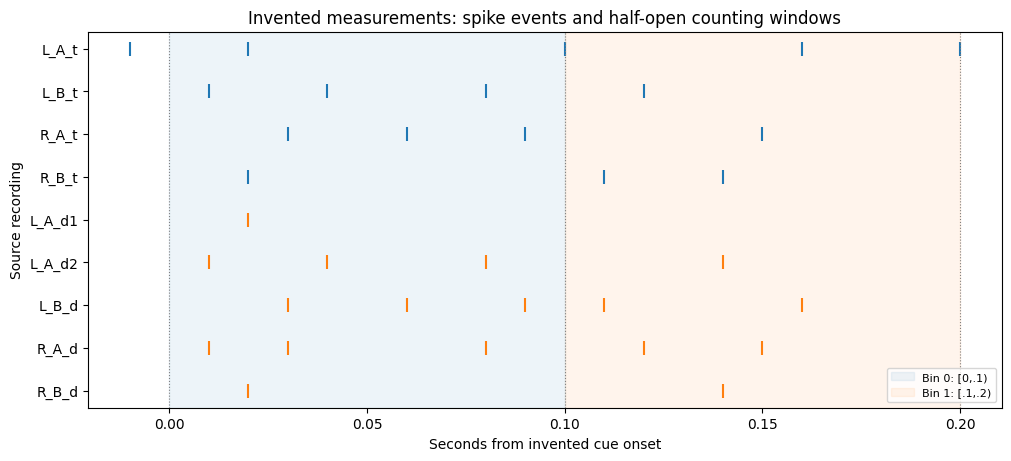

In [2]:
counts = {}
values = np.full((len(sources), len(blocks), len(edges) - 1), np.nan)
observed = np.zeros(values.shape[:2], dtype=bool)
for i, (sid, block, split, pair, times) in enumerate(sources):
    spikes = np.asarray(times)
    counts[sid] = np.array([np.sum((spikes >= left) & (spikes < right))
                            for left, right in zip(edges[:-1], edges[1:])])
    outside = np.sum((spikes < edges[0]) | (spikes >= edges[-1]))
    assert counts[sid].sum() + outside == len(spikes)
    ui = blocks.index(block)
    values[i, ui] = counts[sid]
    observed[i, ui] = True
np.testing.assert_array_equal(counts['L_A_t'], [1, 2])
np.testing.assert_array_equal(counts['L_A_d1'], [1, 0])
assert np.isnan(values[~observed]).all()
show_table(['Source', 'Bin 0 count', 'Bin 1 count'],
           [(sid, *counts[sid]) for sid, *_ in sources])
print('Source tensor:', values.shape, '| observation mask:', observed.shape)
print('First source tensor slice:'); print(values[0])

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
ax.axvspan(0, .1, color='tab:blue', alpha=.08, label='Bin 0: [0,.1)')
ax.axvspan(.1, .2, color='tab:orange', alpha=.08, label='Bin 1: [.1,.2)')
for i, (sid, block, split, pair, times) in enumerate(sources):
    ax.scatter(times, [i] * len(times), marker='|', s=95,
               color='tab:blue' if split == 'train' else 'tab:orange')
for boundary in edges:
    ax.axvline(boundary, color='0.5', linestyle=':', linewidth=.8)
ax.set(yticks=range(len(sources)), yticklabels=[s[0] for s in sources],
       xlabel='Seconds from invented cue onset', ylabel='Source recording',
       title='Invented measurements: spike events and half-open counting windows')
ax.invert_yaxis(); ax.legend(loc='lower right', fontsize=8)
display(fig); plt.close(fig)

## 2. Assemble whole blocks inside the declared split

A row for `1→2` combines one left and one right source with that condition.
Copy both bins from each chosen source together. The first training row is
`L_A_t + R_A_t = [[1,2], [3,1]]`: units run down the rows, time across columns.
In the real pipeline each block may contribute several units, all copied together.

We write the recipes explicitly to expose lineage. Four training pseudorows use
only four distinct sources. Repeating a recipe doubles the row count, not the
evidence. Development uses five different sources to make three rows; its two
`1→2` rows reuse `R_A_d`. Contributor disjointness across splits does not make rows
within a split independent.

Our development class counts are deliberately **2 versus 1** to make the metric
arithmetic informative. Production notebooks balance constructed conditions. Neither
choice tells you how many independent sources support each class.

| Split | Pseudorow | Left source | Right source | Pair |
| --- | --- | --- | --- | --- |
| train | 0 | L_A_t | R_A_t | 1->2 |
| train | 1 | L_B_t | R_B_t | 2->1 |
| train | 2 | L_A_t | R_A_t | 1->2 |
| train | 3 | L_B_t | R_B_t | 2->1 |
| development | 0 | L_A_d1 | R_A_d | 1->2 |
| development | 1 | L_A_d2 | R_A_d | 1->2 |
| development | 2 | L_B_d | R_B_d | 2->1 |

Train row×unit×bin: (4, 2, 2) | development: (3, 2, 2)
Distinct contributing sources: 4 train / 5 development
Wrong row-first split would share: ['L_A_t', 'R_A_t']


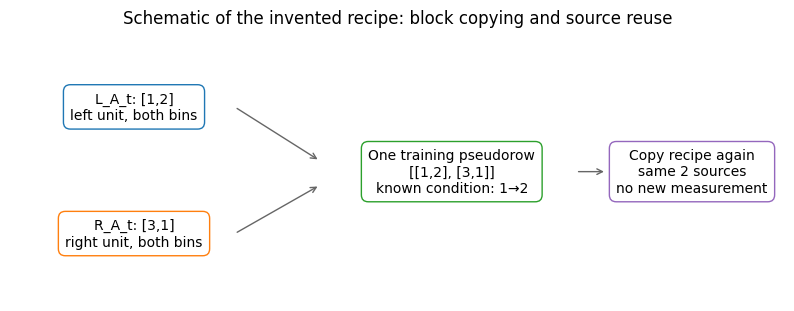

In [3]:
train_recipes = [('L_A_t', 'R_A_t'), ('L_B_t', 'R_B_t'),
                 ('L_A_t', 'R_A_t'), ('L_B_t', 'R_B_t')]
dev_recipes = [('L_A_d1', 'R_A_d'), ('L_A_d2', 'R_A_d'), ('L_B_d', 'R_B_d')]

def assemble(recipes, split):
    rows, labels = [], []
    for recipe in recipes:
        chosen = [by_id[sid] for sid in recipe]
        assert tuple(s[1] for s in chosen) == blocks
        assert all(s[2] == split for s in chosen)
        assert len({s[3] for s in chosen}) == 1
        rows.append(np.stack([counts[sid] for sid in recipe]))
        labels.append(chosen[0][3])
    return np.stack(rows).astype(float), np.array(labels)

train, train_y = assemble(train_recipes, 'train')
development, dev_y = assemble(dev_recipes, 'development')
train_ids = {sid for recipe in train_recipes for sid in recipe}
dev_ids = {sid for recipe in dev_recipes for sid in recipe}
assert not train_ids & dev_ids
np.testing.assert_array_equal(train[0], [[1, 2], [3, 1]])
show_table(['Split', 'Pseudorow', 'Left source', 'Right source', 'Pair'],
           [(split, i, *recipe, labels[i])
            for split, recipes, labels in [('train', train_recipes, train_y),
                                          ('development', dev_recipes, dev_y)]
            for i, recipe in enumerate(recipes)])
print('Train row×unit×bin:', train.shape, '| development:', development.shape)
print('Distinct contributing sources:', len(train_ids), 'train /', len(dev_ids), 'development')

# Counterexample only: splitting already assembled rows 0 and 2 would leak BOTH sources.
wrong_train = set(train_recipes[0])
wrong_development = set(train_recipes[2])
assert wrong_train & wrong_development == {'L_A_t', 'R_A_t'}
print('Wrong row-first split would share:', sorted(wrong_train & wrong_development))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis('off')
for x, y, text, color in [(.16, .72, 'L_A_t: [1,2]\nleft unit, both bins', 'tab:blue'),
                         (.16, .25, 'R_A_t: [3,1]\nright unit, both bins', 'tab:orange'),
                         (.57, .48, 'One training pseudorow\n[[1,2], [3,1]]\nknown condition: 1→2', 'tab:green'),
                         (.88, .48, 'Copy recipe again\nsame 2 sources\nno new measurement', 'tab:purple')]:
    ax.text(x, y, text, ha='center', va='center', fontsize=10,
            bbox=dict(boxstyle='round,pad=.5', facecolor='white', edgecolor=color))
for start, end in [((.29,.72),(.40,.52)), ((.29,.25),(.40,.43)), ((.73,.48),(.77,.48))]:
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color='0.4'))
ax.set_title('Schematic of the invented recipe: block copying and source reuse')
display(fig); plt.close(fig)

## 3. Calculate normalization from training only

For each unit, pool the training rows and bins. Both units have the same multiset
`[1,2,3,1]` repeated twice, so their mean is **7/4 = 1.75** and their population
standard deviation (`ddof=0`) is **√11/4 ≈ .829156**. Thus counts 1, 2 and 3 become
`−3/√11`, `1/√11` and `5/√11`. This matches the pooled-unit scaling convention of
the practical notebooks; it is not per-trial normalization.

Apply these same two numbers to development. Re-estimating them on development
would let evaluation observations change the transformation. The same training
rule can also give heavily reused sources extra weight; that is why lineage matters
even before an encoder. Here repeated training recipes have equal multiplicity.

In [4]:
mean = train.mean(axis=(0, 2))
scale = train.std(axis=(0, 2), ddof=0)
np.testing.assert_allclose(mean, [7/4, 7/4])
np.testing.assert_allclose(scale, [np.sqrt(11)/4] * 2)
train_z = (train - mean[None, :, None]) / scale[None, :, None]
dev_z = (development - mean[None, :, None]) / scale[None, :, None]
show_table(['Unit', 'Training mean', 'Training scale'],
           [(unit, f'{m:.6f}', f'{s:.6f}') for unit, m, s in zip(blocks, mean, scale)])
show_table(['Count', 'Frozen standardized value'],
           [(count, f'{(count - mean[0])/scale[0]:.6f}') for count in [0, 1, 2, 3]])
print('First development row, standardized units×bins:'); print(np.round(dev_z[0], 6))
assert train_z.shape == train.shape and dev_z.shape == development.shape

| Unit | Training mean | Training scale |
| --- | --- | --- |
| L | 1.750000 | 0.829156 |
| R | 1.750000 | 0.829156 |

| Count | Frozen standardized value |
| --- | --- |
| 0 | -2.110579 |
| 1 | -0.904534 |
| 2 | 0.301511 |
| 3 | 1.507557 |

First development row, standardized units×bins:
[[-0.904534 -2.110579]
 [ 1.507557  0.301511]]


## 4. Make features with a given projection, then given logits

Use the **hand-chosen** column `P = [−1,+1]/√2`. It measures right-minus-left
standardized activity at each bin. This reduces two unit coordinates to one; it
discards their common activity level. It is **not a fitted PCA component**. Actual
PCA learns a basis from training data in Chapter 2; CEBRA learns a nonlinear mapping
in Chapter 3. This fixed example isolates what transforming a tensor means.

Transpose `row×unit×bin` to `row×bin×unit`, multiply by P, then concatenate bins.
The features now have shape `row×2`: one coordinate at bin 0 followed by bin 1.
Give the decoder weights `[√22/8,0]` and bias `−.5`, yielding score q. The zero
second weight deliberately ignores bin 1 for easy arithmetic; practical whole-cue
decoders can use every feature. These weights were supplied, not learned.

For class order `[1→2,2→1]`, logits are `[q,−q]`. Development scores are
**[.5,−.5,−1.5]**. Softmax turns each two-logit row into probabilities. It does
not guarantee calibration merely because they sum to one.

In [5]:
projection = np.array([[-1.], [1.]]) / np.sqrt(2)  # Given, never fitted.
train_coordinates = train_z.transpose(0, 2, 1) @ projection
dev_coordinates = dev_z.transpose(0, 2, 1) @ projection
train_features = train_coordinates.reshape(len(train), -1)
dev_features = dev_coordinates.reshape(len(development), -1)
given_weights = np.array([np.sqrt(22)/8, 0.])
given_bias = -.5
q = dev_features @ given_weights + given_bias
np.testing.assert_allclose(q, [.5, -.5, -1.5])
logits = np.column_stack([q, -q])
exp_logits = np.exp(logits - logits.max(axis=1, keepdims=True))
probabilities = exp_logits / exp_logits.sum(axis=1, keepdims=True)
classes = np.array(['1->2', '2->1'])
predicted = classes[probabilities.argmax(axis=1)]
np.testing.assert_allclose(probabilities.sum(axis=1), 1)
show_table(['Dev row', 'True pair', 'Projected bin 0', 'Projected bin 1', 'q',
            'P(1→2)', 'P(2→1)', 'Prediction'],
           [(i, dev_y[i], *(f'{v:.6f}' for v in dev_features[i]), f'{q[i]:.2f}',
             *(f'{v:.6f}' for v in probabilities[i]), predicted[i])
            for i in range(len(development))])
print('Projection shape:', projection.shape, '| coordinate tensor:', dev_coordinates.shape,
      '| readout feature matrix:', dev_features.shape)

| Dev row | True pair | Projected bin 0 | Projected bin 1 | q | P(1→2) | P(2→1) | Prediction |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 1->2 | 1.705606 | 1.705606 | 0.50 | 0.731059 | 0.268941 | 1->2 |
| 1 | 1->2 | 0.000000 | 0.852803 | -0.50 | 0.268941 | 0.731059 | 2->1 |
| 2 | 2->1 | -1.705606 | -0.852803 | -1.50 | 0.047426 | 0.952574 | 2->1 |

Projection shape: (2, 1) | coordinate tensor: (3, 2, 1) | readout feature matrix: (3, 2)


## 5. Reconcile predictions, errors and metrics

The prediction sequence is `[1→2,2→1,2→1]`; the middle row is wrong. Counts with
true classes down rows and predicted classes across columns are **[[1,1],[0,1]]**.
Ordinary accuracy is 2/3. Class recalls are 1/2 and 1, so balanced accuracy is
**(1/2+1)/2 = 3/4**. The difference comes from unequal class counts, not two
inconsistent definitions of correctness.

Log loss uses the probabilities of the true labels: approximately .731059, .268941
and .952574. Their ordinary row-mean negative natural log is **.558370 nats**, compared with
`ln(2) ≈ .693147` for uniform probabilities. Those numbers establish the arithmetic
of a supplied decoder on three invented rows. They establish no trained-model skill,
statistical significance or biological result; two development rows even share a source.

| Quantity | Calculated value |
| --- | --- |
| Accuracy | 0.666667 |
| Balanced accuracy | 0.750000 |
| Log loss (nats) | 0.558370 |
| Uniform loss (nats) | 0.693147 |

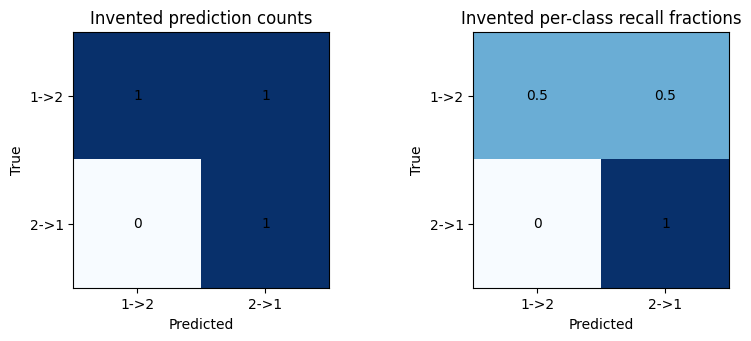

In [6]:
confusion = np.zeros((len(classes), len(classes)), dtype=int)
class_index = {label: i for i, label in enumerate(classes)}
for truth, prediction in zip(dev_y, predicted):
    confusion[class_index[truth], class_index[prediction]] += 1
recall = np.diag(confusion) / confusion.sum(axis=1)
accuracy = np.trace(confusion) / confusion.sum()
balanced_accuracy = recall.mean()
true_probability = probabilities[np.arange(len(dev_y)), [class_index[y] for y in dev_y]]
log_loss = -np.log(true_probability).mean()
np.testing.assert_array_equal(confusion, [[1, 1], [0, 1]])
np.testing.assert_allclose([accuracy, balanced_accuracy, log_loss],
                           [2/3, 3/4, .5583702422033958])
show_table(['Quantity', 'Calculated value'], [('Accuracy', f'{accuracy:.6f}'),
           ('Balanced accuracy', f'{balanced_accuracy:.6f}'),
           ('Log loss (nats)', f'{log_loss:.6f}'), ('Uniform loss (nats)', f'{np.log(2):.6f}')])
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), constrained_layout=True)
for ax, matrix, title in zip(axes, [confusion, confusion / confusion.sum(axis=1, keepdims=True)],
                           ['Invented prediction counts', 'Invented per-class recall fractions']):
    ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f'{value:g}', ha='center', va='center')
    ax.set(xticks=[0, 1], xticklabels=classes, yticks=[0, 1], yticklabels=classes,
           xlabel='Predicted', ylabel='True', title=title)
display(fig); plt.close(fig)

## 6. Calculate one CEBRA contrastive term without training CEBRA

Return to the **training** tensor. Take `train row 0, bin 0` as reference and its
adjacent `bin 1` as positive. Choose both bins of training row 1 as a sampled
negative bank. This is a possible native-bin draw; it does not cross a row boundary.
The known labels helped assemble the rows, even though temporal adjacency chooses
the positive.

Now **supply** normalized 2D encoder outputs for those four inputs. These vectors
are hypothetical values, not outputs obtained by fitting a network. The actual
workflow uses eight-dimensional outputs. At temperature 1, one reference's loss is
`−dot(reference, positive) + log Σ exp(dot(reference, negative_j))`.
CEBRA's sampled denominator does not explicitly append the positive, so this is
not a classification probability and the term can be negative.

Initially the reference is `[1,0]`, positive `[0,1]`, and negatives `[0,1]`, `[-1,0]`.
The term is **0 + ln(1+e⁻¹) = .313262**. Change only the given positive to `[1,0]`:
the term becomes **−1 + ln(1+e⁻¹) = −.686738**. Increasing positive similarity lowers
this term when the negative similarities stay fixed. A real gradient update changes
shared network parameters and can affect many positives and negatives together.
This comparison is a hand calculation, not an optimizer trace or convergence evidence.

In [7]:
print('Reference source recipe:', train_recipes[0], 'bin 0:', train[0, :, 0].tolist())
print('Positive source recipe:', train_recipes[0], 'bin 1:', train[0, :, 1].tolist())
print('Negative-bank source recipe:', train_recipes[1], 'both bins:', train[1].tolist())
reference = np.array([1., 0.])
positive_initial = np.array([0., 1.])
positive_changed = np.array([1., 0.])
negative_bank = np.array([[0., 1.], [-1., 0.]])
np.testing.assert_allclose(np.linalg.norm(np.vstack([reference, positive_initial,
                                                   positive_changed, negative_bank]), axis=1), 1)
negative_similarity = negative_bank @ reference
negative_term = np.logaddexp.reduce(negative_similarity)
initial_term = -(reference @ positive_initial) + negative_term
changed_term = -(reference @ positive_changed) + negative_term
np.testing.assert_allclose([initial_term, changed_term],
                           [.31326168751822286, -.6867383124817772])
show_table(['Given encoder outputs', 'Positive cosine', 'Negative cosines', 'One loss term'],
           [('Initial assignment', reference @ positive_initial, negative_similarity.tolist(), f'{initial_term:.6f}'),
            ('Changed assignment', reference @ positive_changed, negative_similarity.tolist(), f'{changed_term:.6f}')])
print('A real batch averages such reference terms. No encoder or decoder was fitted here.')

Reference source recipe: ('L_A_t', 'R_A_t') bin 0: [1.0, 3.0]
Positive source recipe: ('L_A_t', 'R_A_t') bin 1: [2.0, 1.0]
Negative-bank source recipe: ('L_B_t', 'R_B_t') both bins: [[3.0, 1.0], [1.0, 2.0]]


| Given encoder outputs | Positive cosine | Negative cosines | One loss term |
| --- | --- | --- | --- |
| Initial assignment | 0.0 | [0.0, -1.0] | 0.313262 |
| Changed assignment | 1.0 | [0.0, -1.0] | -0.686738 |

A real batch averages such reference terms. No encoder or decoder was fitted here.


## Check your understanding, with answers

1. **Does moving the `.10` spike in `L_A_t` to `.099` preserve its count vector?**
   No: [1,2] becomes [2,1]. Total cue count remains three; timing changes.
2. **Can you split the two copies of the first recipe across train and development?**
   No: both would contain `L_A_t` and `R_A_t`. Separate pseudorow IDs do not separate
   their measurements. Actual predecessor dependencies must also remain separated.
3. **What changed in the incorrectly predicted development row?**
   Its bin-0 counts are [3,3], so the difference projection is zero and q is −.5.
   The given decoder prefers `2→1`, although the known assembly condition was `1→2`.
4. **Would a lower contrastive term guarantee better endpoint decoding?**
   No. The hand change only improves a similarity objective. A decoder must be
   evaluated separately on the declared development construction.

You can now identify the object at every stage: timestamps → count/mask tensor →
source recipe → standardized unit vectors → projected bin features → logits →
probabilities → errors. The practical chapters replace these tiny hand-specified
choices with audited source inputs and explicitly fitted methods. Their scientific
validity still depends on source support, selection, confounds and the claim being
made; successful arithmetic cannot resolve those questions by itself.